# Lab 12: Social and Media Platform APIs

*INFO 4617/5617 · Week 12 · Chapter 12, [Social and Media Platform APIs](https://cuinfoscience.github.io/Web-Data-Science-Book/ch-12-social.html)*

This week every class is live coding: one lab in three parts, one a day. Each step says what we're building and why. Its code cells hold a comment saying what to write, and we write the code together. Cells that start with `# Given:` are already written: we read them together and run them. Nothing here is turned in. After each step, a **💬 Discuss** box holds questions to talk over; click it to open it.

We read what U.S. federal agencies post, on two platforms:
- **Part 1, Monday:** who is posting. Bluesky's public API answers anyone, with no account and no key. We ask it for one agency's profile, and check two ways of telling an agency's account from an impostor's.
- **Part 2, Wednesday:** an agency's posts: one page by hand, then six months of them, and when the agency posts.
- **Part 3, Friday:** YouTube's Data API, which needs a key, for the same agencies' videos.

Reddit's archives and Spotify are in the chapter. Along the way, short ⏱ microsprints ask you to change one thing, alone or in pairs, and share what you find.

**Before class:** open this notebook in the `webdata` environment (chapter 1), and have your email address ready for the User-Agent. Monday and Wednesday need no key. **For Friday, get a YouTube Data API key** from a personal Google account, starting at <https://console.cloud.google.com/apis/library/youtube.googleapis.com> ("Before Step 8: get your YouTube key", at the start of Part 3, walks through it with screenshots), and store it as the environment variable `YOUTUBE_KEY`, one of week 11's safe ways: set it, quit Jupyter, close the terminal, open a new one, and start Jupyter from there.

On Wednesday and Friday, start at that day's setup step.

> **Instructor key.** Rebuilt on 2026-11-10 from chapter 12's Learning Objectives, after the audit of the previous key (issue #168); it follows the textbook at commit 3036573. Run on 2026-11-10 with `labs/tools/run_key.py`: every cell of Parts 1 and 2 ran live. A rerun should match the shape of every output, and the six months of Step 6 (472 posts from May 1 up to November 1, 2026) and their weekday and hour counts, unless the Weather Service deletes a post. It won't match follower counts, likes and reposts, or the newest posts in Steps 5 and 6, which change daily. `noaa.gov`'s failure in Step 2 comes from a second record on NOAA's domain, and can clear without notice. The checkpoints in `labs/week-12/data/`, `accounts.csv` and `nws_posts.csv`, were saved by this run's own cells; for the run, `data_base` pointed at the run's folder, and it was then set back to the repository's address on `main`. **Part 3 is not run live:** the cloud machine has no `YOUTUBE_KEY`, so the cells that need it (Step 8's key cells, and Steps 9 and 10) are tagged `not-run-live` and have no outputs. Run them from a laptop with a key before Friday. Step 8's microsprint, which sends a made-up key, did run. Step 11's answers about YouTube are general until Part 3 runs.

# Part 1 — Monday: who is posting

Bluesky is a social network built on an open protocol, the AT Protocol. Its public API answers anyone who asks, with no account and no key. Today we ask it for one agency's profile, by hand; check two proofs that an account is the agency's; then ask for five agencies in one request, and save what we found.

## Step 0 — Set up (4 minutes)

Put your email address in the User-Agent, and run the given cell. Bluesky asks for no key, but every request still says who sent it, as Wikipedia's did in week 10. Every request this week goes to Bluesky's public **AppView**, `https://public.api.bsky.app/xrpc`, the service that answers reads for anyone ([API hosts](https://bsky.network/docs/advanced-guides/api-directory/)). Each **method**, one kind of request, puts its name in the address, and has a page in Bluesky's [HTTP reference](https://endpoints.bsky.app/) listing its parameters and the fields it returns.

In [1]:
# Given: Part 1's setup. Put your email address in HEADERS, then run it
import requests
import pandas as pd

HEADERS = {"User-Agent": "WebDataScience/1.0 (your-email@colorado.edu)"}
bsky_base = "https://public.api.bsky.app/xrpc"

<details>
<summary>💬 Discuss</summary>

- In week 11, the Census Bureau and FRED wanted a key; Bluesky wants none. What does a key let a provider do that Bluesky gives up?
- The chapter dates every rule it states about a platform ("as of November 2026"). Why does a platform's API need a date more than the Census Bureau's does?

</details>

## Step 1 — One agency's profile, by hand (12 minutes)

Open the National Weather Service's profile on the website, [bsky.app/profile/nws.noaa.gov](https://bsky.app/profile/nws.noaa.gov). Now ask the API for it with [`app.bsky.actor.getProfile`](https://endpoints.bsky.app/#bluesky-app/tag/appbskyactor/GET/xrpc/app.bsky.actor.getProfile), whose parameter `actor` takes the account's handle. Bluesky answers an error as JSON with a `"message"`, so print the status code and `.get("message")` first: `.get()` gives the value if the key is there, and `None` if it isn't. Then look at the keys before reading one. See the chapter's ["Who Is Posting: A Profile"](https://cuinfoscience.github.io/Web-Data-Science-Book/ch-12-social.html#who-is-posting-a-profile).

In [2]:
# profile_url: f"{bsky_base}/app.bsky.actor.getProfile"
# profile_params: a dictionary whose "actor" is "nws.noaa.gov"
profile_url = f"{bsky_base}/app.bsky.actor.getProfile"
profile_params = {"actor": "nws.noaa.gov"}

In [3]:
# Send it with params=profile_params and headers=HEADERS; keep its .json() in profile
profile_response = requests.get(profile_url, params=profile_params, headers=HEADERS)
profile = profile_response.json()

In [4]:
# Print the status code and profile.get("message"): None means there was no error
print(profile_response.status_code, profile.get("message"))

200 None


In [5]:
# Look at the answer's keys
profile.keys()

dict_keys(['did', 'handle', 'displayName', 'avatar', 'associated', 'labels', 'createdAt', 'verification', 'description', 'indexedAt', 'banner', 'followersCount', 'followsCount', 'postsCount'])

In [6]:
# Print its "followersCount" and "postsCount"
print(profile["followersCount"], profile["postsCount"])

63392 1410


In [7]:
# Print its "did", the account's permanent ID
print(profile["did"])

did:plc:pfot5zyhod4cxwc5gfhzds4i


<details>
<summary>💬 Discuss</summary>

- Did the API's counts match the website's, which rounds them? If they differ by a few, why might that be?
- A handle can change; the `did` can't. Which would you store, if you meant to collect the same accounts again next year?
- Typed as `"handle"` instead of `"actor"`, this request gets status 400 and the message `Missing required key "actor"`. Without the print, which line would have stopped first, and with what error?

</details>

## Step 2 — Two proofs: a domain, and a check (16 minutes)

The handle `nws.noaa.gov` is a domain name. An account can take a domain as its handle only by proving it controls the domain ([Bluesky's guide](https://bsky.social/about/blog/4-28-2023-domain-handle-tutorial)), so no one else can post as `nws.noaa.gov`. The blue check on the website is a second proof: Bluesky has **verified** the account, and says so in the `verification` field ([how verification works](https://bsky.social/about/blog/04-21-2025-verification)). [`.endswith()`](https://docs.python.org/3/builtins/stdtypes.html#str.endswith) asks whether a string ends a certain way.

In [8]:
# Print profile["verification"]
print(profile["verification"])

{'verifications': [{'issuer': 'did:plc:z72i7hdynmk6r22z27h6tvur', 'issuerDisplayName': 'Bluesky', 'issuerHandle': 'bsky.app', 'uri': 'at://did:plc:z72i7hdynmk6r22z27h6tvur/app.bsky.graph.verification/3lv3tnpqc7a2p', 'isValid': True, 'createdAt': '2025-07-29T09:55:09.448Z'}], 'verifiedStatus': 'valid', 'trustedVerifierStatus': 'none'}


In [9]:
# Print its "verifiedStatus", one level down
print(profile["verification"]["verifiedStatus"])

valid


In [10]:
# Is the handle a .gov domain? Print profile["handle"].endswith(".gov")
print(profile["handle"].endswith(".gov"))

True


In [11]:
# Given: NOAA Fisheries' profile. Its handle ends in .gov, but it has no "verification":
# fisheries["verification"] would stop with a KeyError, so .get() gives "none"
fisheries_params = {"actor": "fisheries.noaa.gov"}
fisheries_response = requests.get(profile_url, params=fisheries_params, headers=HEADERS)
fisheries = fisheries_response.json()
print(fisheries["handle"], fisheries["handle"].endswith(".gov"))
print(fisheries.get("verification", "none"))

fisheries.noaa.gov True
none


### ⏱ Microsprint (5 minutes, alone or in pairs)

NOAA, the agency the Weather Service and NOAA Fisheries belong to, has had an account since January 2025, with the handle `noaa.gov`. A domain proves a handle through a record that names one account; `noaa.gov`'s record now names two, NOAA's and NOAA Fisheries', and the protocol's [handle rules](https://atproto.com/specs/handle#handle-resolution) say to trust neither.

**Do:** ask for the profile of `"noaa.gov"`, with names of your own, and print the status code and the message. Then run the given cell, which asks for the same account by its `did`.
**Share:** what came back each way, and whether NOAA has an account on Bluesky.

In [12]:
# Microsprint: noaa_params, "actor" "noaa.gov"; send it; print the status and "message"
noaa_params = {"actor": "noaa.gov"}
noaa_response = requests.get(profile_url, params=noaa_params, headers=HEADERS)
noaa = noaa_response.json()
print(noaa_response.status_code, noaa.get("message"))

400 Profile not found


In [13]:
# Given: the same account, asked for by its did instead of its handle
noaa_did_params = {"actor": "did:plc:ncviqcnllx42n36oqftjsqwj"}
noaa_did_response = requests.get(profile_url, params=noaa_did_params, headers=HEADERS)
noaa_by_did = noaa_did_response.json()
print(noaa_by_did["handle"], "|", noaa_by_did["displayName"])
print(noaa_by_did["followersCount"], noaa_by_did.get("verification", "none"))

handle.invalid | NOAA
41932 none


<details>
<summary>💬 Discuss</summary>

- NOAA Fisheries has a `.gov` handle and no check. Which proof would you trust more, the domain or the check, and why?
- NOAA's account still exists, but its handle now reads `handle.invalid`, because of a record on NOAA's own domain. What does a `.gov` handle prove, and for how long?
- An account named like an agency, with neither proof, posts about the agency's work. What would a study that collected its posts as the agency's get wrong?

</details>

## Step 3 — Five agencies at once (18 minutes)

[`app.bsky.actor.getProfiles`](https://endpoints.bsky.app/#bluesky-app/tag/appbskyactor/GET/xrpc/app.bsky.actor.getProfiles) takes up to 25 handles in one request, as `actors`, plural. Give it a Python list, and `requests` sends the parameter once for each handle. Its answer holds a list, `"profiles"`, and leaves out any handle it can't find, with no error: compare how many you asked for with how many came back. The given cell's `for` loop runs its indented lines once for each profile; `[:10]` keeps a date's first ten characters. See ["Several Accounts at Once"](https://cuinfoscience.github.io/Web-Data-Science-Book/ch-12-social.html#several-accounts-at-once).

In [14]:
# agencies: a list of five handles, "nws.noaa.gov", "climate.noaa.gov",
# "noaacomms.noaa.gov", "fisheries.noaa.gov", and "federalreserve.gov"
agencies = ["nws.noaa.gov", "climate.noaa.gov", "noaacomms.noaa.gov",
            "fisheries.noaa.gov", "federalreserve.gov"]

In [15]:
# profiles_url: f"{bsky_base}/app.bsky.actor.getProfiles"
# profiles_params: "actors" (plural) is agencies
profiles_url = f"{bsky_base}/app.bsky.actor.getProfiles"
profiles_params = {"actors": agencies}

In [16]:
# Send it; keep its .json() in profiles_data; print the status code and its "message"
profiles_response = requests.get(profiles_url, params=profiles_params, headers=HEADERS)
profiles_data = profiles_response.json()
print(profiles_response.status_code, profiles_data.get("message"))

200 None


In [17]:
# profiles: profiles_data["profiles"]; print how many we asked for, and how many came back
profiles = profiles_data["profiles"]
print(len(agencies), "asked for,", len(profiles), "came back")

5 asked for, 5 came back


In [18]:
# Given: one row for each profile that came back, the most followed first
rows = []
for p in profiles:
    rows.append({"handle": p["handle"], "did": p["did"], "name": p["displayName"],
                 "followers": p["followersCount"], "posts": p["postsCount"],
                 "joined": p["createdAt"][:10]})
accounts = pd.DataFrame(rows).sort_values("followers", ascending=False)
accounts

,handle,did,name,followers,posts,joined
0,nws.noaa.gov,did:plc:pfot5zyhod4cxwc5gfhzds4i,National Weather Service,63392,1410,2025-01-17
1,climate.noaa.gov,did:plc:ybhjcsleqxtr2oyxiq7jijr7,NOAA Climate.gov,46995,93,2025-01-14
4,federalreserve.gov,did:plc:d3vmaxc5ytftnf4gwdwptupg,Federal Reserve,8413,1041,2024-12-06
2,noaacomms.noaa.gov,did:plc:y5f5pym22pcxpoc6bdgdyr6i,NOAA Communications,5623,119,2025-01-14
3,fisheries.noaa.gov,did:plc:nco5iyuk5726eauqhdzvavkt,NOAA Fisheries,792,495,2025-06-18


In [19]:
# Given: write down the day we collected it, and save the table as Monday's checkpoint
accounts["collected"] = pd.Timestamp.now(tz="UTC").strftime("%Y-%m-%d")
accounts.to_csv("accounts.csv", index=False)

In [20]:
# Given, only if the cells above stopped: remove the "#" from the next two lines,
# and run this cell. It loads the table the key's run saved on 2026-11-10
# data_base = "https://raw.githubusercontent.com/cuinfoscience/INFO4617-Fall2026/main/labs/week-12/data/"
# accounts = pd.read_csv(data_base + "accounts.csv")

### ⏱ Microsprint (4 minutes, alone or in pairs)

**Do:** make a list of your own, `more_agencies`, of `agencies` plus `"noaa.gov"` and `"stlouisfed.bsky.social"` (the Federal Reserve Bank of St. Louis, FRED's home in week 11); send it as `"actors"`, and print both counts.
**Share:** how many handles you asked for, how many profiles came back, which one is missing, and whether anything warned you.

In [21]:
# Microsprint: more_agencies = agencies + ["noaa.gov", "stlouisfed.bsky.social"]
# Send it as "actors" in more_params; print how many we asked for, and how many came back
more_agencies = agencies + ["noaa.gov", "stlouisfed.bsky.social"]
more_params = {"actors": more_agencies}
more_response = requests.get(profiles_url, params=more_params, headers=HEADERS)
more_data = more_response.json()
print(len(more_agencies), "asked for,", len(more_data["profiles"]), "came back")

7 asked for, 6 came back


<details>
<summary>💬 Discuss</summary>

- The Federal Reserve joined in December 2024, before the four NOAA accounts, and has about 13 percent of the Weather Service's followers in the key's run. Is followers the right measure of an agency's reach?
- We chose agencies whose handles are `.gov` domains. Which agencies would a study of "government on Bluesky" built this way never see?
- `accounts.csv` holds the day it was collected. What can a saved copy not tell you that the live request can?

</details>

## End of Part 1

On Wednesday, Part 2 reads the Weather Service's posts: one page by hand, then six months of them by following the `cursor`, and when it posts. It starts with its own setup step and loads today's table, so you don't need today's cells to have run.

**Before Friday:** get your YouTube Data API key, from a personal Google account, and store it as `YOUTUBE_KEY`. Start at <https://console.cloud.google.com/apis/library/youtube.googleapis.com>, and follow "Before Step 8: get your YouTube key", at the start of Part 3.

# Part 2 — Wednesday: an agency's posts, page after page

One request returns at most 100 posts. Today we read one page of the Weather Service's posts by hand, keeping other people's posts out; follow the `cursor` to the next page, as week 10 followed Wikipedia's `continue`; let a given loop collect six months; and ask when the agency posts, and which posts travel.

## Step 4 — Set up again (4 minutes)

Part 2 starts fresh, so a student who missed Monday can start here. Put your email address in the User-Agent, and run the given cell. It imports what we need, sets the address of today's one method, [`app.bsky.feed.getAuthorFeed`](https://endpoints.bsky.app/#bluesky-app/tag/appbskyfeed/GET/xrpc/app.bsky.feed.getAuthorFeed), and loads Monday's table from the course's repository. `time` is for the given loop's pause of a second between requests.

In [22]:
# Given: Part 2's setup. Put your email address in HEADERS, then run it.
# It loads Monday's table, saved by the key's run on 2026-11-10
import time
import requests
import pandas as pd
import matplotlib.pyplot as plt

HEADERS = {"User-Agent": "WebDataScience/1.0 (your-email@colorado.edu)"}
bsky_base = "https://public.api.bsky.app/xrpc"
feed_url = f"{bsky_base}/app.bsky.feed.getAuthorFeed"
data_base = "https://raw.githubusercontent.com/cuinfoscience/INFO4617-Fall2026/main/labs/week-12/data/"
accounts = pd.read_csv(data_base + "accounts.csv")
accounts

,handle,did,name,followers,posts,joined,collected
0,nws.noaa.gov,did:plc:pfot5zyhod4cxwc5gfhzds4i,National Weather Service,63392,1410,2025-01-17,2026-11-10
1,climate.noaa.gov,did:plc:ybhjcsleqxtr2oyxiq7jijr7,NOAA Climate.gov,46995,93,2025-01-14,2026-11-10
2,federalreserve.gov,did:plc:d3vmaxc5ytftnf4gwdwptupg,Federal Reserve,8413,1041,2024-12-06,2026-11-10
3,noaacomms.noaa.gov,did:plc:y5f5pym22pcxpoc6bdgdyr6i,NOAA Communications,5623,119,2025-01-14,2026-11-10
4,fisheries.noaa.gov,did:plc:nco5iyuk5726eauqhdzvavkt,NOAA Fisheries,792,495,2025-06-18,2026-11-10


<details>
<summary>💬 Discuss</summary>

- Monday's table gives the Weather Service's `posts`. How many requests of 100 would it take to read them all, and what might that count include that a list of its own posts leaves out?

</details>

## Step 5 — One page of posts, by hand (15 minutes)

[`getAuthorFeed`](https://endpoints.bsky.app/#bluesky-app/tag/appbskyfeed/GET/xrpc/app.bsky.feed.getAuthorFeed) returns an account's posts, newest first, up to 100 a request (`limit`). With `filter` set to `"posts_no_replies"` it leaves out the account's replies, but keeps its **reposts**: other people's posts it shared, perhaps private people's, each marked with a `"reason"`. Read one page, and one item, by hand. The given cell keeps the agency's own posts: `"reason" in one_item` is `True` when the item has that key, and `continue` skips to the next item. See ["An Account's Posts"](https://cuinfoscience.github.io/Web-Data-Science-Book/ch-12-social.html#an-accounts-posts).

In [23]:
# feed_params: "actor" "nws.noaa.gov", "limit" 25, "filter" "posts_no_replies"
feed_params = {"actor": "nws.noaa.gov", "limit": 25, "filter": "posts_no_replies"}

In [24]:
# Send it to feed_url; keep its .json() in first_page; print the status code and "message"
feed_response = requests.get(feed_url, params=feed_params, headers=HEADERS)
first_page = feed_response.json()
print(feed_response.status_code, first_page.get("message"))

200 None


In [25]:
# Look at first_page's keys
first_page.keys()

dict_keys(['feed', 'cursor'])

In [26]:
# feed: first_page["feed"], a list; print len(feed) and first_page["cursor"]
feed = first_page["feed"]
print(len(feed), first_page["cursor"])

25 2026-10-28T14:13:35.352Z


In [27]:
# item: feed[0], the first item; look at its keys ("reason" would mean a repost)
item = feed[0]
item.keys()

dict_keys(['post'])

In [28]:
# post: item["post"]; print post["record"]["createdAt"],
# then post["likeCount"] and post["repostCount"]
post = item["post"]
print(post["record"]["createdAt"], post["likeCount"], post["repostCount"])

2026-11-10T01:51:09.493Z 102 29


In [29]:
# Print the post's text: post["record"]["text"]
print(post["record"]["text"])

You may have heard there is a threat for snow in the Northeast/Mid-Atlantic late this week. Here is the latest information on that possibility. Please stay weather aware at weather.gov for the latest on the storm!


In [30]:
# Given: one row for each of the agency's own posts on this page, skipping reposts
page_rows = []
for one_item in feed:
    if "reason" in one_item:
        continue
    one_post = one_item["post"]
    record = one_post["record"]
    page_rows.append({"created": record["createdAt"], "likes": one_post["likeCount"],
                      "reposts": one_post["repostCount"], "text": record["text"][:60]})
page_posts = pd.DataFrame(page_rows)
print(len(feed), "items,", len(page_posts), "of them the agency's own posts")
page_posts.head()

25 items, 25 of them the agency's own posts


,created,likes,reposts,text
0,2026-11-10T01:51:09.493Z,102,29,You may have heard there is a threat for snow ...
1,2026-11-09T16:35:09.710Z,59,12,Heavy to excessive rainfall is possible over s...
2,2026-11-09T12:15:08.700Z,65,15,A short week of Weather101 includes our first ...
3,2026-11-08T19:02:17.497Z,81,13,"Showers and thunderstorms, some severe, will b..."
4,2026-11-06T19:19:57.936Z,111,28,A chilly evening for the areas in blue/purple ...


### ⏱ Microsprint (4 minutes, alone or in pairs)

**Do:** ask for Climate.gov's newest 25 items, `"climate.noaa.gov"`, with names of your own; then run the given cell, which counts the reposts without printing whose posts they are.
**Share:** how many of the 25 items were reposts, and how many were Climate.gov's own posts.

In [31]:
# Microsprint: climate_params like feed_params, but "actor" is "climate.noaa.gov";
# send it; keep its .json() in climate_page; climate_feed: climate_page["feed"]
climate_params = {"actor": "climate.noaa.gov", "limit": 25, "filter": "posts_no_replies"}
climate_response = requests.get(feed_url, params=climate_params, headers=HEADERS)
climate_page = climate_response.json()
climate_feed = climate_page["feed"]

In [32]:
# Given: count the reposts in climate_feed, without printing whose posts they are
reposts = 0
for one_item in climate_feed:
    if "reason" in one_item:
        reposts += 1
print(len(climate_feed), "items,", reposts, "of them reposts")

25 items, 1 of them reposts


<details>
<summary>💬 Discuss</summary>

- Each post carries two times: `createdAt`, set by the author's app, and `indexedAt`, when Bluesky saw it. Which would you use to say when an agency posted, and why say which in what you write?
- We skipped reposts to keep other people's posts, perhaps private people's, out of our table. What does an agency's reposting tell you that its own posts don't, and how could you study it without printing anyone's handle?

</details>

## Step 6 — The `cursor`: page two by hand, then six months given (17 minutes)

The answer ended with a **cursor**. Send it back as the `cursor` parameter, and the next request returns the page that follows; an answer with no cursor is the last. As with week 10's `continue`, you send back what the server gave you without needing to know what it means. Ask for page two by hand. Then a given loop follows the cursor, a second between requests, until its posts are older than `since`; a given cell keeps those up to `until`. See ["More Than One Page"](https://cuinfoscience.github.io/Web-Data-Science-Book/ch-12-social.html#more-than-one-page-the-cursor).

In [33]:
# second_params: feed_params's three keys and values, plus "cursor": first_page["cursor"]
second_params = {"actor": "nws.noaa.gov", "limit": 25, "filter": "posts_no_replies",
                 "cursor": first_page["cursor"]}

In [34]:
# Send it; keep its .json() in second_page; print the status code and its "message"
second_response = requests.get(feed_url, params=second_params, headers=HEADERS)
second_page = second_response.json()
print(second_response.status_code, second_page.get("message"))

200 None


In [35]:
# second_feed: second_page["feed"]; print the createdAt of its first post,
# second_feed[0]["post"]["record"]["createdAt"], and then second_page["cursor"]
second_feed = second_page["feed"]
print(second_feed[0]["post"]["record"]["createdAt"])
print(second_page["cursor"])

2026-10-28T00:37:11.778Z
2026-10-15T15:50:36.454Z


In [36]:
# The six months we keep: since = "2026-05-01", until = "2026-11-01"
since = "2026-05-01"
until = "2026-11-01"

In [37]:
# Given: pages of 100 posts, a second apart, keeping the agency's own. "while True"
# repeats until "break": when an answer has no cursor, or when the last post kept,
# nws_rows[-1], is older than since. The "embed" is what the post carries, or "none"
loop_params = {"actor": "nws.noaa.gov", "limit": 100, "filter": "posts_no_replies"}
nws_rows = []
while True:
    page = requests.get(feed_url, params=loop_params, headers=HEADERS).json()
    for one_item in page["feed"]:
        if "reason" in one_item:
            continue
        one_post = one_item["post"]
        record = one_post["record"]
        nws_rows.append({"created": record["createdAt"], "likes": one_post["likeCount"],
                         "reposts": one_post["repostCount"],
                         "embed": record.get("embed", {}).get("$type", "none")})
    if "cursor" not in page or nws_rows[-1]["created"] < since:
        break
    loop_params["cursor"] = page["cursor"]
    time.sleep(1)
print(len(nws_rows), "posts, back to", nws_rows[-1]["created"])

495 posts, back to 2026-04-28T14:26:40.823Z


In [38]:
# Given: a DataFrame of the posts, with times pandas can compare, from since up to until
nws = pd.DataFrame(nws_rows)
nws["created"] = pd.to_datetime(nws["created"], format="ISO8601", utc=True)
nws = nws[(nws["created"] >= since) & (nws["created"] < until)]
print(len(nws), "posts from", since, "up to", until)

472 posts from 2026-05-01 up to 2026-11-01


In [39]:
# Given: write down the day we collected them, and save them as Wednesday's checkpoint
nws["collected"] = pd.Timestamp.now(tz="UTC").strftime("%Y-%m-%d")
nws.to_csv("nws_posts.csv", index=False)

In [40]:
# Given, only if the loop above stopped: remove the "#" from the next two lines, and run
# this cell. It loads the posts the key's run collected on 2026-11-10, May to October 2026
# nws = pd.read_csv(data_base + "nws_posts.csv")
# nws["created"] = pd.to_datetime(nws["created"], format="ISO8601", utc=True)

### ⏱ Microsprint (4 minutes, alone or in pairs)

A misspelled value doesn't always get an error.

**Do:** ask for the Weather Service's newest 100 items with the filter misspelled, `"posts_no_reply"`, with names of your own, and print the status code and message; then run the given cell, which counts the replies (an item that is a reply has a `"reply"` key). [`getAuthorFeed`'s reference](https://endpoints.bsky.app/#bluesky-app/tag/appbskyfeed/GET/xrpc/app.bsky.feed.getAuthorFeed) lists the values `filter` takes.
**Share:** the status code, and how many of the 100 items were replies.

In [41]:
# Microsprint: typo_params: "actor" "nws.noaa.gov", "limit" 100, "filter" "posts_no_reply"
# send it; keep its .json() in typo_page; print the status code and its "message"
typo_params = {"actor": "nws.noaa.gov", "limit": 100, "filter": "posts_no_reply"}
typo_response = requests.get(feed_url, params=typo_params, headers=HEADERS)
typo_page = typo_response.json()
print(typo_response.status_code, typo_page.get("message"))

200 None


In [42]:
# Given: count the items that are replies, without printing them or whom they answer
replies = 0
for one_item in typo_page["feed"]:
    if "reply" in one_item:
        replies += 1
print(len(typo_page["feed"]), "items,", replies, "of them replies")

100 items, 21 of them replies


<details>
<summary>💬 Discuss</summary>

- The loop stops on a date, not on a count of pages. When would you stop on a count, on a date, or only at the end, and how would a reader of your study know which you chose?
- In the key's run, the misspelled filter came back with status 200 and 21 replies among its 100 items. A misspelled parameter name, `"Cursor"` for `"cursor"`, is ignored the same way: page two comes back as page one. What in your code would catch either mistake?
- The loop assumes every request works. If Bluesky answered one page with a 429, which line would fail, and what would `nws_rows` hold? How does the chapter's `raise_for_status()` change that?

</details>

## Step 7 — When an agency posts, and what travels (14 minutes)

Each `createdAt` is in UTC (Coordinated Universal Time). Convert the times to the agency's own time zone, Eastern for the Weather Service's headquarters, with [`dt.tz_convert()`](https://pandas.pydata.org/docs/reference/api/pandas.Series.dt.tz_convert.html); name each one's weekday with [`dt.day_name()`](https://pandas.pydata.org/docs/reference/api/pandas.Series.dt.day_name.html); and count them with [`value_counts()`](https://pandas.pydata.org/docs/reference/api/pandas.Series.value_counts.html). `reindex(days)` puts the counts in Monday-to-Sunday order. Given cells plot them, and compare posts by what they carry. See ["When an Agency Posts"](https://cuinfoscience.github.io/Web-Data-Science-Book/ch-12-social.html#when-an-agency-posts-and-what-travels).

In [43]:
# local: nws["created"].dt.tz_convert("America/New_York")
local = nws["created"].dt.tz_convert("America/New_York")

In [44]:
# day_names: local.dt.day_name(); look at the first five with .head()
day_names = local.dt.day_name()
day_names.head()

16    Saturday
17      Friday
18      Friday
19      Friday
20      Friday
Name: created, dtype: str

In [45]:
# Given: the days of the week, in order
days = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

In [46]:
# by_day: day_names.value_counts(), then .reindex(days); print it
by_day = day_names.value_counts().reindex(days)
print(by_day)

created
Monday        78
Tuesday       74
Wednesday     73
Thursday      79
Friday       109
Saturday      20
Sunday        39
Name: count, dtype: int64


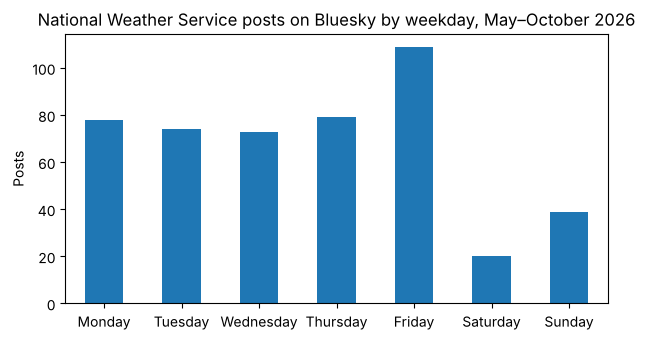

In [47]:
# Given: the counts as bars, titled with the account and the six months
fig, ax = plt.subplots(figsize=(7, 3.5))
by_day.plot.bar(ax=ax, rot=0)
ax.set(title="National Weather Service posts on Bluesky by weekday, May–October 2026",
       ylabel="Posts", xlabel="")
plt.show()

### ⏱ Microsprint (4 minutes, alone or in pairs)

**Do:** count the posts by hour of the day instead, with `local.dt.hour`, and print the three busiest hours; then do the same with `nws["created"].dt.hour`, which is still in UTC.
**Share:** the Weather Service's busiest hour in Eastern time, and in UTC.

In [48]:
# Microsprint: by_hour: local.dt.hour.value_counts(); print its .head(3);
# then utc_hour, the same from nws["created"].dt.hour
by_hour = local.dt.hour.value_counts()
print(by_hour.head(3))
utc_hour = nws["created"].dt.hour.value_counts()
print(utc_hour.head(3))

created
10    55
11    53
13    40
Name: count, dtype: int64
created
14    55
15    53
17    40
Name: count, dtype: int64


In [49]:
# Given: posts grouped by what they carry (images, a video, a link card, a quoted post,
# or none), with how many there are and their median reposts
embeds = nws.groupby("embed")["reposts"].agg(["count", "median"])
embeds.sort_values("count", ascending=False)

,count,median
embed,,
app.bsky.embed.images,395,19.0
app.bsky.embed.video,55,22.0
app.bsky.embed.external,13,14.0
app.bsky.embed.recordWithMedia,4,28.0
none,3,28.0
app.bsky.embed.record,2,26.5


<details>
<summary>💬 Discuss</summary>

- The weather doesn't take weekends off. Why might an agency's posts?
- In the key's run, the busiest hour was 10 a.m. in Eastern time, and 14:00 in UTC. Which claims about when an agency posts would a forgotten conversion break?
- In the key's run, 395 of the 472 posts carried images. What does that do to a comparison of images with videos, and what would you need, beyond this table, to say a format causes reposts?

</details>

## End of Part 2

On Friday, Part 3 asks YouTube's Data API about the same agencies' videos. It needs a key: get it today if you haven't, from a personal Google account, and store it as `YOUTUBE_KEY` ("Before Step 8: get your YouTube key", just below, starting at <https://console.cloud.google.com/apis/library/youtube.googleapis.com>). Part 3 starts with its own setup step and loads this week's tables, so you don't need today's cells to have run.

# Part 3 — Friday: YouTube's Data API, and a key that counts

YouTube answers anyone with a key, and counts every request against the key's daily quota. We test the key, read one of Google's error messages on purpose, find an agency's channel by its handle, and read its newest videos' statistics.

## Before Step 8: get your YouTube key (15 minutes, before class)

Do this before Friday's class: Google's console is built for companies that run many services, and the page you need is several menus deep. Start from this link, which opens the YouTube Data API's own page in the console:

> **<https://console.cloud.google.com/apis/library/youtube.googleapis.com>**

1. **Sign in, and choose a project.** Sign in with a **personal** Google account. If the console asks you to select a project, choose **New Project**, name it (`info4617` will do), and click **Create**. A project is what Google counts the quota against.
2. **Enable the API.** Check that the page names **YouTube Data API v3** ①, and click **Enable** ②.

   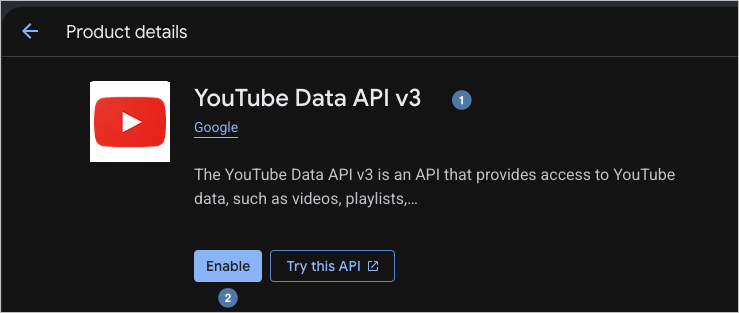

3. **Open Credentials.** The page becomes **API/Service Details**, and its Status reads **Enabled** ①. Click the **Credentials** tab ②.

   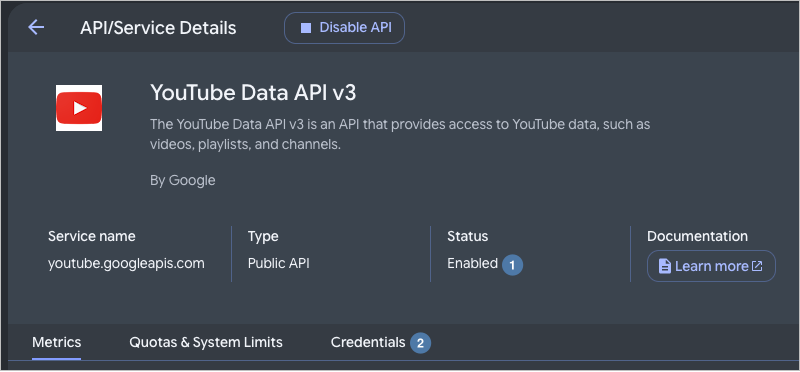

4. **Create an API key.** Click **Create credentials** ① and choose **API key** ②. Not **OAuth client ID**: that is for a program acting on a person's own YouTube account, which we never do.

   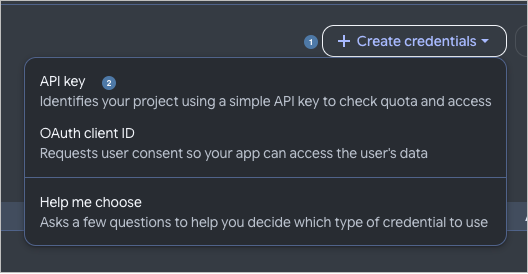

5. **Restrict the key to YouTube.** In the **Create API key** dialog, give the key a name ①. Skip past the blue **Service account required** note: it is about Gemini, which we aren't using. Open **Select API restrictions**, tick **YouTube Data API v3** ②, and click **OK** ③. Leave **Application restrictions** at **None** ④: your laptop's IP address changes from one network to the next. Then click **Create** at the foot of the dialog.

   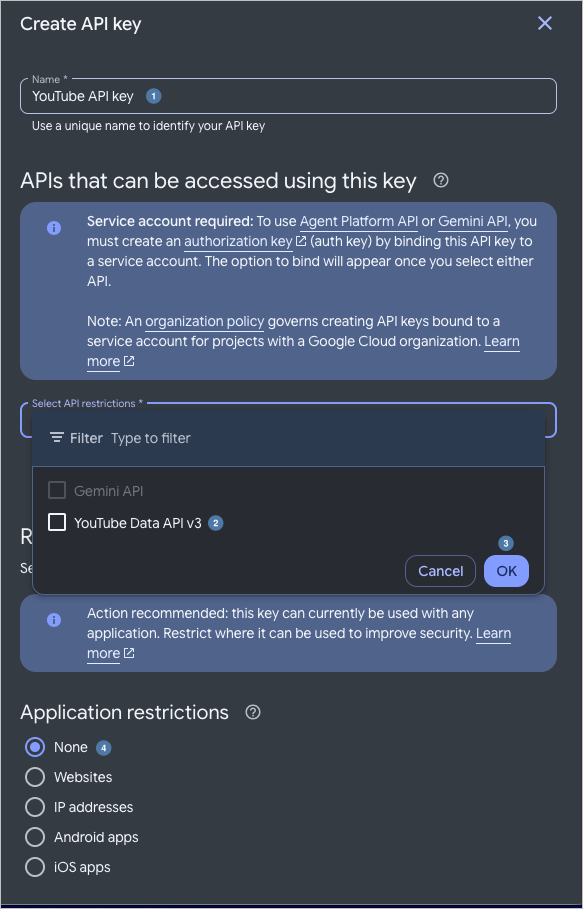

6. **Copy the key**, and paste it only into the next step: never into a notebook cell, a code file, or a message. If you lose it, or it leaks, delete it on the Credentials page and make a new one.
7. **Store it** as `YOUTUBE_KEY` with the `webdata` environment, in a terminal (on Windows, the Anaconda Prompt), with your key in place of `your-key`:

   ```
   conda env config vars set YOUTUBE_KEY="your-key" -n webdata
   ```

   Then **quit Jupyter, close that terminal, open a new one**, run `conda activate webdata`, and start Jupyter from it. A terminal reads its environment variables when it opens, so one opened before you set the key doesn't have it. Week 11's other safe ways, a JSON file kept out of git or `getpass()`, work too.

The same steps, with the screenshots' full captions, are in the chapter's ["Getting and Storing a Key"](https://cuinfoscience.github.io/Web-Data-Science-Book/ch-12-social.html#getting-and-storing-a-key). Screenshots: the Google Cloud console in Firefox, 2026-11-06.

## Step 8 — Set up, and test your key (8 minutes)

Put your email address in the User-Agent, and run the given cell: it says whether `YOUTUBE_KEY` is set, without printing it, and loads this week's tables. If it says `MISSING`, quit Jupyter, open a new terminal, and start Jupyter from there; if you can't restart now, the next given cell asks for the key with [`getpass()`](https://docs.python.org/3/library/getpass.html). Then a given request tests the key. YouTube answers an error as JSON, under `"error"`, with a `"message"` ([errors](https://developers.google.com/youtube/data/reference/rest/v3/errors)).

In [50]:
# Given: Part 3's setup. Put your email address in HEADERS, then run it. It says whether
# YOUTUBE_KEY is set, without printing it, and loads Monday's and Wednesday's tables,
# saved by the key's run on 2026-11-10
import os
import requests
import pandas as pd

HEADERS = {"User-Agent": "WebDataScience/1.0 (your-email@colorado.edu)"}
print("YOUTUBE_KEY:", "set" if os.environ.get("YOUTUBE_KEY") else "MISSING")
yt_base = "https://www.googleapis.com/youtube/v3"
channels_url = f"{yt_base}/channels"
data_base = "https://raw.githubusercontent.com/cuinfoscience/INFO4617-Fall2026/main/labs/week-12/data/"
accounts = pd.read_csv(data_base + "accounts.csv")
nws = pd.read_csv(data_base + "nws_posts.csv")

YOUTUBE_KEY: MISSING


In [ ]:
# Given: only if the check said MISSING, ask for the key (getpass hides what you paste)
from getpass import getpass
if not os.environ.get("YOUTUBE_KEY"):
    os.environ["YOUTUBE_KEY"] = getpass("YOUTUBE_KEY isn't set. Paste it here: ")

In [ ]:
# Now it's set: read it into youtube_key with os.environ["YOUTUBE_KEY"]
youtube_key = os.environ["YOUTUBE_KEY"]

In [ ]:
# Given: one request (1 unit of your quota) to test the key. It prints Google's message
# if the key is refused
test_params = {"part": "id", "forHandle": "@NOAA", "key": youtube_key}
test_response = requests.get(channels_url, params=test_params, headers=HEADERS)
test = test_response.json()
print(test_response.status_code, test.get("error", {}).get("message", "The key works"))

### ⏱ Microsprint (4 minutes, alone or in pairs)

**Do:** send the same request with a made-up key, `"not-a-real-key"`, with names of your own, and print the status code and the answer's `"error"`.
**Share:** the status code, Google's `"message"`, and the `"reason"` in its `"errors"` list.

In [54]:
# Microsprint: bad_params like test_params, but "key" is "not-a-real-key"; send it to
# channels_url; keep its .json() in bad; print the status code and bad["error"]
bad_params = {"part": "id", "forHandle": "@NOAA", "key": "not-a-real-key"}
bad_response = requests.get(channels_url, params=bad_params, headers=HEADERS)
bad = bad_response.json()
print(bad_response.status_code, bad["error"])

400 {'code': 400, 'message': 'API key not valid. Please pass a valid API key.', 'errors': [{'message': 'API key not valid. Please pass a valid API key.', 'domain': 'global', 'reason': 'badRequest'}], 'status': 'INVALID_ARGUMENT', 'details': [{'@type': 'type.googleapis.com/google.rpc.ErrorInfo', 'reason': 'API_KEY_INVALID', 'domain': 'googleapis.com', 'metadata': {'service': 'youtube.googleapis.com'}}, {'@type': 'type.googleapis.com/google.rpc.LocalizedMessage', 'locale': 'en-US', 'message': 'API key not valid. Please pass a valid API key.'}]}


<details>
<summary>💬 Discuss</summary>

- Bluesky asked for no key; YouTube does. What does a key let Google do that Bluesky can't?
- The key travels in the URL, so `test_response.url` contains it. Where could it end up if you printed the URL?
- Google's quota page says a refused request costs a unit too. If the made-up key had been your real key with a typo, whose quota would have paid?

</details>

## Step 9 — A channel by its handle (12 minutes)

[`channels.list`](https://developers.google.com/youtube/data/reference/rest/v3/channels/list) finds a channel by its handle with `forHandle` (the `@` is optional). `part` names the groups of fields you want back, each described in the [channel resource](https://developers.google.com/youtube/data/reference/rest/v3/channels): `snippet` (the name), `statistics` (the counts), and `contentDetails`, which holds the ID of the playlist of every video the channel has uploaded. The answer's `"items"` is a list of the channels found. Ask for NOAA's, `@NOAA`, and compare it with [its page](https://www.youtube.com/@NOAA). See ["A Channel by Its Handle"](https://cuinfoscience.github.io/Web-Data-Science-Book/ch-12-social.html#a-channel-by-its-handle).

In [ ]:
# channel_params: "part" "snippet,statistics,contentDetails", "forHandle" "@NOAA",
# and "key" youtube_key
channel_params = {"part": "snippet,statistics,contentDetails", "forHandle": "@NOAA",
                  "key": youtube_key}

In [ ]:
# Send it to channels_url; keep its .json() in channel_data; print its .get("error")
channel_response = requests.get(channels_url, params=channel_params, headers=HEADERS)
channel_data = channel_response.json()
print(channel_data.get("error"))

In [ ]:
# channel: the first of channel_data["items"]; print its snippet's "title"
channel = channel_data["items"][0]
print(channel["snippet"]["title"])

In [ ]:
# Print its statistics' "subscriberCount" and "videoCount"
print(channel["statistics"]["subscriberCount"], channel["statistics"]["videoCount"])

In [ ]:
# uploads: channel["contentDetails"]["relatedPlaylists"]["uploads"]; print it
uploads = channel["contentDetails"]["relatedPlaylists"]["uploads"]
print(uploads)

### ⏱ Microsprint (4 minutes, alone or in pairs)

**Do:** ask for another agency's channel, `@NOAAClimate`, `@NOAAFisheries` or `@federalreserve`, with `"part"` `"statistics"` and names of your own, and print its statistics.
**Share:** the channel, its subscribers and videos, and the same agency's Bluesky followers in `accounts`.

In [ ]:
# Microsprint: other_params: "part" "statistics", another agency's "forHandle", and "key";
# send it; keep its .json() in other; print other["items"][0]["statistics"]
other_params = {"part": "statistics", "forHandle": "@NOAAClimate", "key": youtube_key}
other_response = requests.get(channels_url, params=other_params, headers=HEADERS)
other = other_response.json()
print(other["items"][0]["statistics"])

<details>
<summary>💬 Discuss</summary>

- YouTube rounds `subscriberCount` down to three significant figures. What can't you measure because of that?
- On Monday a `.gov` handle helped prove a Bluesky account was the agency's. How would you know `@NOAA` is NOAA's, and where would you check?

</details>

## Step 10 — A channel's newest videos (12 minutes)

[`playlistItems.list`](https://developers.google.com/youtube/data/reference/rest/v3/playlistItems/list) on the uploads playlist returns the newest videos' IDs, up to 50 a request (`maxResults`), with a `nextPageToken` for the next 50, as Bluesky gave a `cursor`. [`videos.list`](https://developers.google.com/youtube/data/reference/rest/v3/videos/list) takes the IDs, joined with commas, and returns each video's `statistics` ([video resource](https://developers.google.com/youtube/data/reference/rest/v3/videos)). Both requests are given; read one video's statistics by hand. Counts arrive as strings, so convert one with `int()`. Each request costs 1 unit of the project's 10,000 a day ([quota costs](https://developers.google.com/youtube/data/determine_quota_cost)).

In [ ]:
# Given: the uploads playlist's newest 50 video IDs (1 unit). It prints Google's error
# (None if none), and the token for the next 50
playlist_params = {"part": "contentDetails", "playlistId": uploads, "maxResults": 50,
                   "key": youtube_key}
playlist_url = f"{yt_base}/playlistItems"
playlist_response = requests.get(playlist_url, params=playlist_params, headers=HEADERS)
playlist = playlist_response.json()
print(playlist.get("error"))
video_ids = []
for one_item in playlist["items"]:
    video_ids.append(one_item["contentDetails"]["videoId"])
print(len(video_ids), "videos; next page:", playlist.get("nextPageToken"))

In [ ]:
# Given: those videos' snippets and statistics (1 unit). ",".join(video_ids) makes
# one string of the IDs, separated by commas
videos_params = {"part": "snippet,statistics", "id": ",".join(video_ids),
                 "key": youtube_key}
videos_response = requests.get(f"{yt_base}/videos", params=videos_params, headers=HEADERS)
videos_data = videos_response.json()
print(videos_data.get("error"))
video_items = videos_data["items"]

In [ ]:
# stats: the first video's statistics, video_items[0]["statistics"]; print it
stats = video_items[0]["statistics"]
print(stats)

In [ ]:
# Print its "viewCount" as a number, with int()
print(int(stats["viewCount"]))

In [ ]:
# Given: one row a video, counts as numbers. A video whose owner hid its likes has
# no "likeCount": .get() gives 0 for it, and we count how often that happened
video_rows = []
no_likes = 0
for v in video_items:
    counts = v["statistics"]
    if "likeCount" not in counts:
        no_likes += 1
    video_rows.append({"published": v["snippet"]["publishedAt"][:10],
                       "title": v["snippet"]["title"][:50],
                       "views": int(counts.get("viewCount", 0)),
                       "likes": int(counts.get("likeCount", 0))})
videos = pd.DataFrame(video_rows)
print(len(videos), "videos;", no_likes, "with no likeCount")
videos.sort_values("views", ascending=False).head(5)

In [ ]:
# Given: write down the day, and save the table on your computer as Friday's checkpoint
videos["collected"] = pd.Timestamp.now(tz="UTC").strftime("%Y-%m-%d")
videos.to_csv("videos.csv", index=False)

<details>
<summary>💬 Discuss</summary>

- These two requests cost 2 units. Using the `videoCount` from Step 9, how many units would all of the channel's videos cost, and could one key collect them in a day?
- We set a missing `likeCount` to 0. When is that wrong, and what does the count of videos with no `likeCount` tell you?
- YouTube's reference says that from August 24, 2026, `viewCount` counts a view the moment a video begins to play, autoplay included. What does that do to a comparison of older and newer videos' views?

</details>

## Step 11 — What did we learn? (3 minutes)

In a few sentences, as comments:

- Monday asked who is posting. How did you tell an agency's account from an impostor's, and what did NOAA's own handle show about the domain proof?
- Bluesky's `cursor` and YouTube's `nextPageToken` both page through a list. What did each ask of you?
- We skipped reposts and never collected a reply. What did that keep out of our data, and what did it cost us?
- Which of this week's numbers would be different if you ran this notebook next week, and which wouldn't?

**Recommended Exercises ahead** (in the chapter's companion notebook, due Sunday):

- Step 1, check who you're asking about: Step 2's `verifiedStatus` and `.endswith(".gov")` on one profile, and Step 3's `getProfiles`, with its count of what came back.
- Step 2, one account's September posts: Step 5's repost skip, and Step 6's cursor by hand and its given loop that stops on a date.
- Step 3, describe the month: Step 7's time zone, weekdays, and `embed` table; the median reposts is one more column.
- Step 4, the second account: Steps 5–7 again, for it.
- Step 5, compare: Step 7's bar chart, with two accounts.
- Step 6, interpret: the Discuss questions after Steps 6 and 7.

In [ ]:
# Your answers here, as comments
# 1. Two proofs: a .gov handle, which only whoever controls the domain can take, and Bluesky's
#    verification. The Weather Service had both; NOAA Fisheries had a .gov handle and no
#    verification. NOAA's own handle, noaa.gov, didn't work at all (400, "Profile not found"),
#    and asked by its did the account was there, as handle.invalid. A domain proves an account
#    only while the domain's records are right; the did is what stays.
# 2. Bluesky's cursor asked only that we send it back: page two by hand, then pages of 100
#    back to 2026-04-28 (495 posts, 472 of them from May through October). YouTube's
#    nextPageToken works the same way, but every page carries the key and costs a unit of the
#    day's 10,000. (Part 3 wasn't run for this key; its numbers come from your own run.)
# 3. The filter and the repost skip kept other people's posts, perhaps private people's, out
#    of our tables: 1 of Climate.gov's newest 25 items was a repost, and the misspelled filter
#    let 21 replies into 100 items. It cost us what an agency chooses to amplify, and whom
#    it answers.
# 4. Follower counts, likes, reposts, the newest posts, and noaa.gov's broken handle can change
#    any day. The May to October window is fixed, so its 472 posts and weekday counts (Friday
#    the busiest, with 109) should hold unless posts are deleted. YouTube's counts change too,
#    and its subscriber counts are rounded, so a small change won't show.

## Friday: your portfolio checkpoint (15 minutes)

The last 15 minutes go to your project. This week's checkpoint, **Collect and clean your data**, is due Sunday, November 8:

- **Collection code** that runs, makes polite requests (a User-Agent that identifies you, pauses between requests), and saves the raw data;
- **a cleaning step**, with its code and output, that produces a tidy dataset;
- **a small sample** of the cleaned data in your repository, with a data dictionary;
- **the README's Data section**: the source, when you collected it, how many records, and what you kept out of the repository and why.

Use the time to run your collection code once, here, where you can ask. If your data comes from a platform, its terms of service decide what you may put in a public repository, and this week's rule holds for your project too: keep private people out of what you save and show.